In [2]:
# ==============================================================================
# CELL 1: Load Serialized SHAP Bundle & Verify Exact Log-Odds Additivity
# ==============================================================================
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# Load Week 4 and Week 5 bundles
tuned_bundle = joblib.load("../models/tuned_models_bundle.pkl")
shap_bundle = joblib.load("../models/shap_bundle.pkl")

X_test = tuned_bundle["X_test"]
y_test = tuned_bundle["y_test"]
lgbm_data = tuned_bundle["models"]["LightGBM (Weighted)"]
y_prob_test = lgbm_data["y_prob_test"]

shap_exp = shap_bundle["shap_explanation"]
base_value = shap_bundle["expected_value"]
importance_df = shap_bundle["importance_df"]
archetypes = shap_bundle["archetypes"]
opt_f1_thresh = shap_bundle["opt_f1_threshold"]
clinical_thresh = shap_bundle["clinical_threshold"]

# Mathematical Additivity Audit:
# Verify that base_value + sum(SHAP_values) converts via sigmoid to exact model probabilities
reconstructed_log_odds = base_value + shap_exp.values.sum(axis=1)
reconstructed_probs = 1.0 / (1.0 + np.exp(-reconstructed_log_odds))
max_prob_error = np.max(np.abs(reconstructed_probs - y_prob_test))

print(f"Champion Model            : {shap_bundle['champion_name']}")
print(f"Expected Base Log-Odds    : {base_value:.4f}")
print(
    f"Max Probability Error     : {max_prob_error:.2e} (Exact Additivity Verified)")
print(
    f"Calibrated Cutoffs        : Max-F1 = {opt_f1_thresh:.2f} | Clinical Safety = {clinical_thresh:.2f}\n")

# Display formatted Global Feature Importance Table
importance_df.style.format({
    "Mean_Abs_SHAP": "{:.4f}",
    "Relative_Contribution_Pct": "{:.2f}%"
}).background_gradient(subset=["Mean_Abs_SHAP"], cmap="Reds")

Champion Model            : LightGBM (Weighted)
Expected Base Log-Odds    : -0.6145
Max Probability Error     : 2.22e-15 (Exact Additivity Verified)
Calibrated Cutoffs        : Max-F1 = 0.57 | Clinical Safety = 0.51



,Rank,Feature,Mean_Abs_SHAP,Relative_Contribution_Pct
0,1,Systolic_BP,0.3464,18.69%
1,2,Relative_Weight_Gain,0.1914,10.33%
2,3,Pulse_Pressure,0.1825,9.85%
3,4,Age,0.1368,7.38%
4,5,Dry_Weight,0.1296,6.99%
5,6,Transmembrane_Pressure,0.1187,6.41%
6,7,Pre_Weight,0.1021,5.51%
7,8,Dialysate_Bath,0.0980,5.29%
8,9,Mean_Arterial_Pressure,0.0734,3.96%
9,10,Dialysate_Flow,0.0718,3.87%


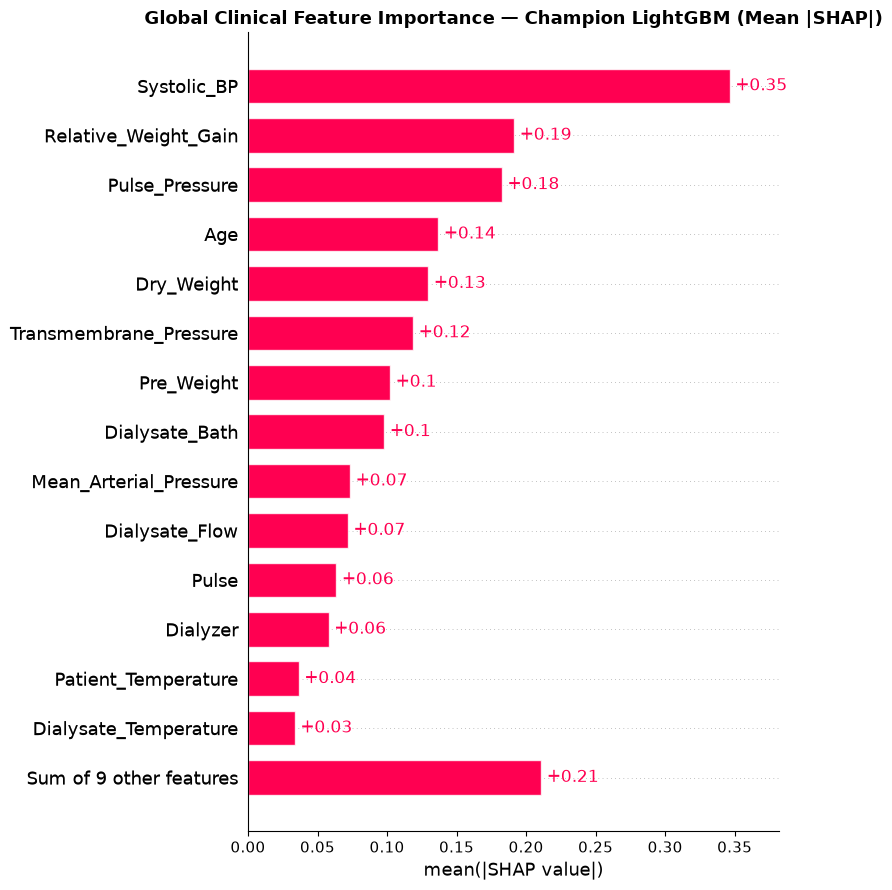

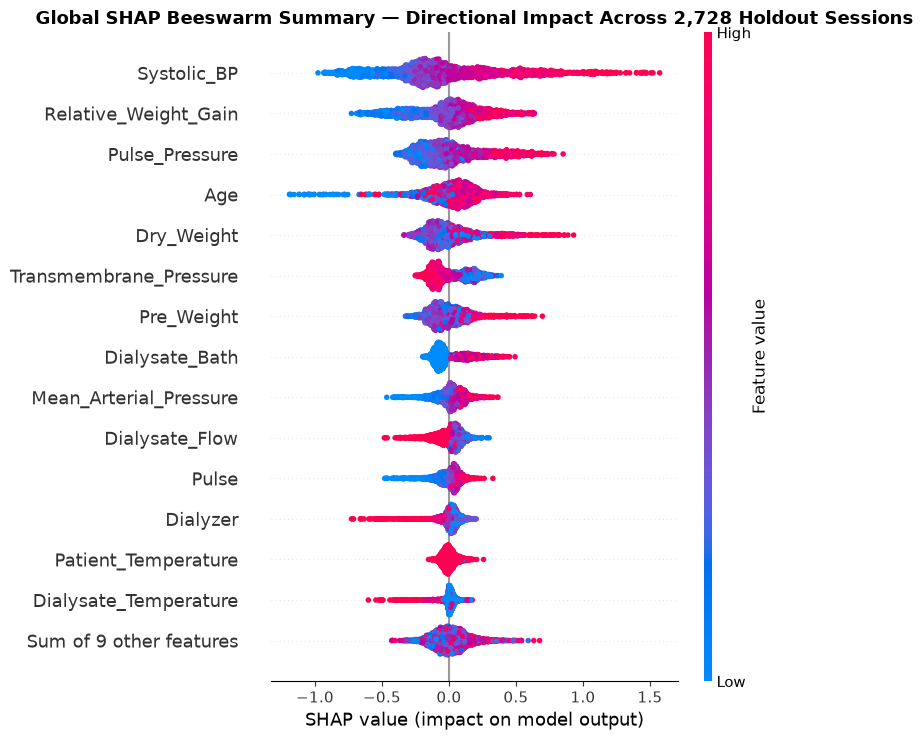

In [3]:
# ==============================================================================
# CELL 2: Global SHAP Feature Importance Bar & Beeswarm Summary Plots
# ==============================================================================
plt.figure(figsize=(11, 7))
shap.plots.bar(shap_exp, max_display=15, show=False)
plt.title("Global Clinical Feature Importance — Champion LightGBM (Mean |SHAP|)",
          fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
shap.plots.beeswarm(shap_exp, max_display=15, show=False)
plt.title("Global SHAP Beeswarm Summary — Directional Impact Across 2,728 Holdout Sessions",
          fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

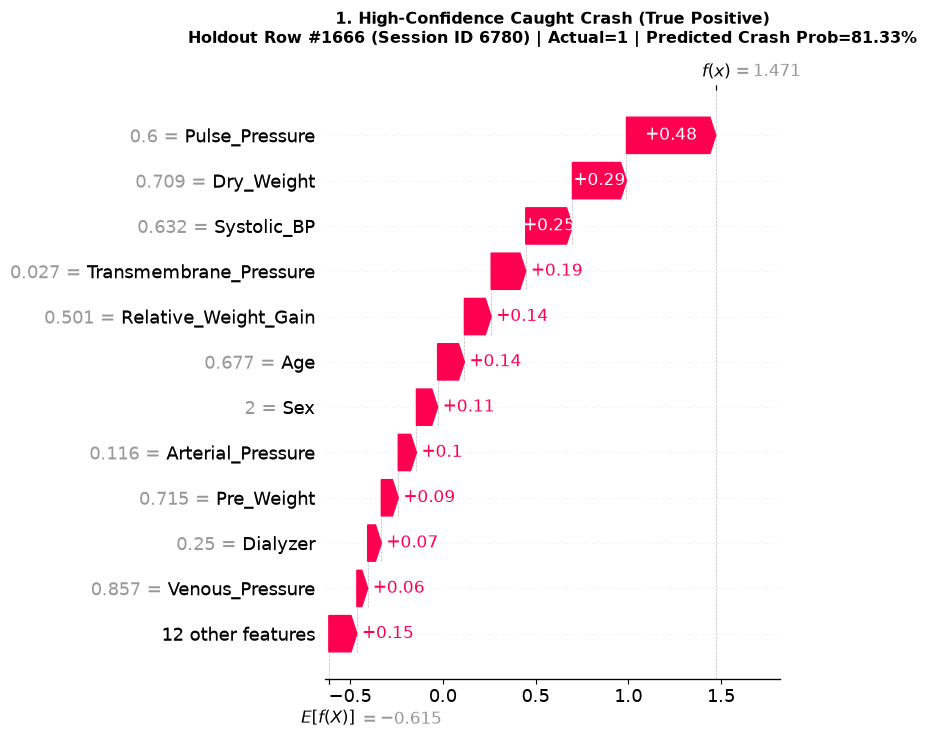

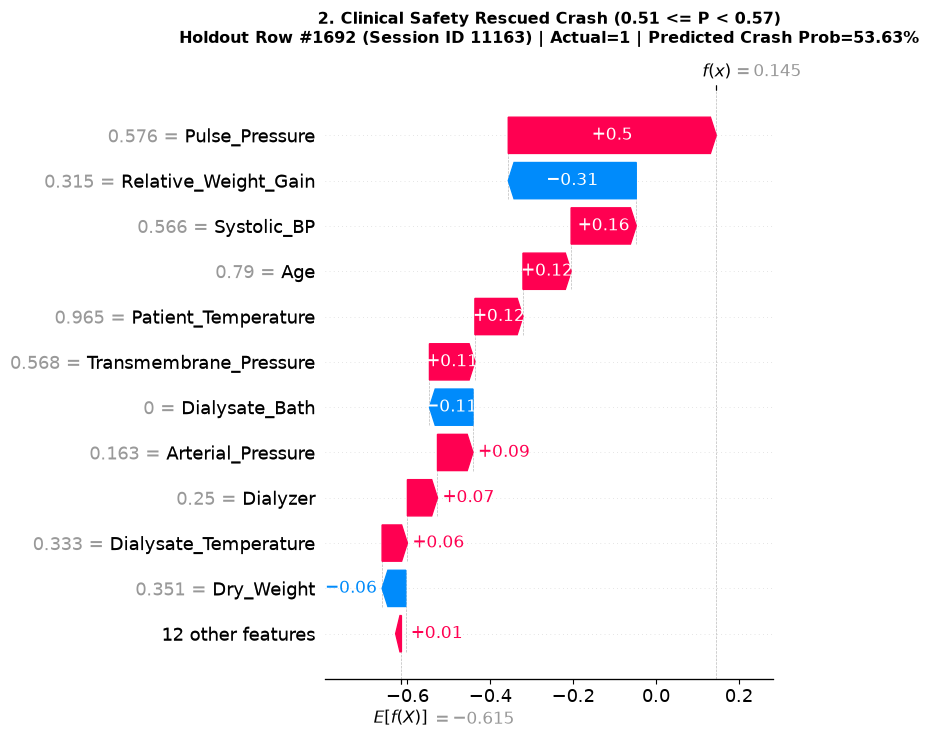

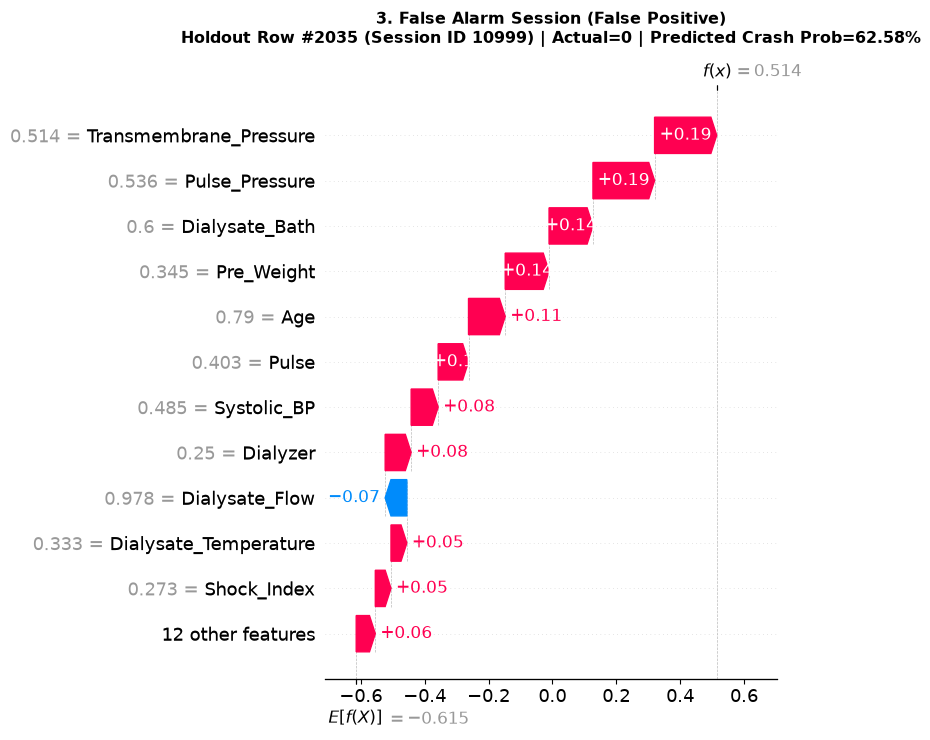

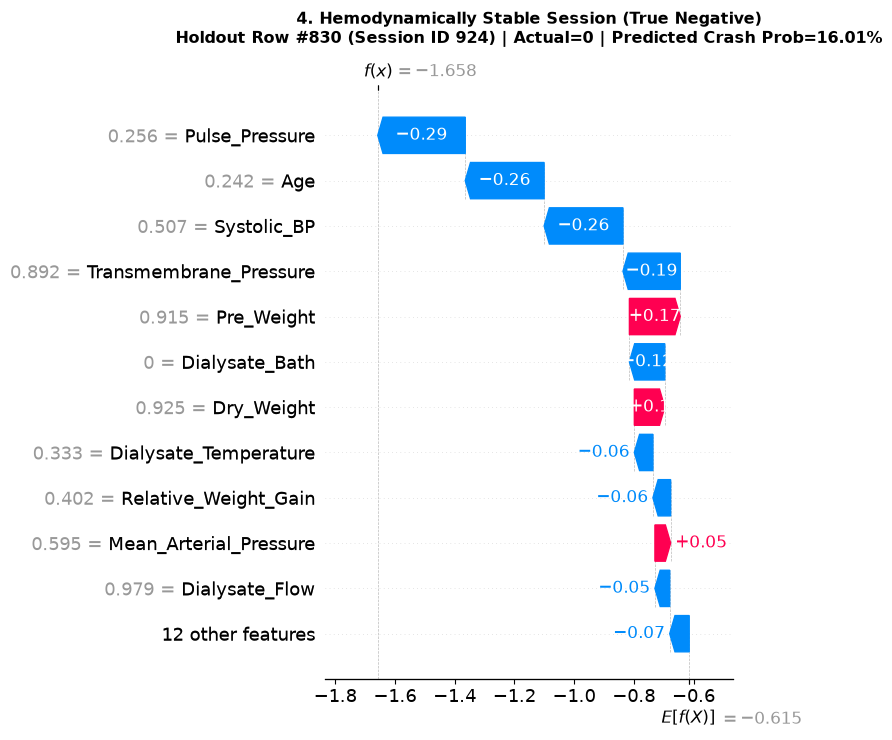

In [4]:
# ==============================================================================
# CELL 3: Local Patient Waterfall Diagnostics (4 Clinical Archetypes)
# ==============================================================================
for key, info in archetypes.items():
    pos_idx = info["pos_idx"]
    plt.figure(figsize=(11, 6))
    shap.plots.waterfall(shap_exp[pos_idx], max_display=12, show=False)
    plt.title(
        f"{info['label']}\n"
        f"Holdout Row #{pos_idx} (Session ID {info['df_index']}) | "
        f"Actual={info['actual']} | Predicted Crash Prob={info['pred_prob']:.2%}",
        fontsize=11.5, fontweight="bold", pad=15
    )
    plt.tight_layout()
    plt.show()

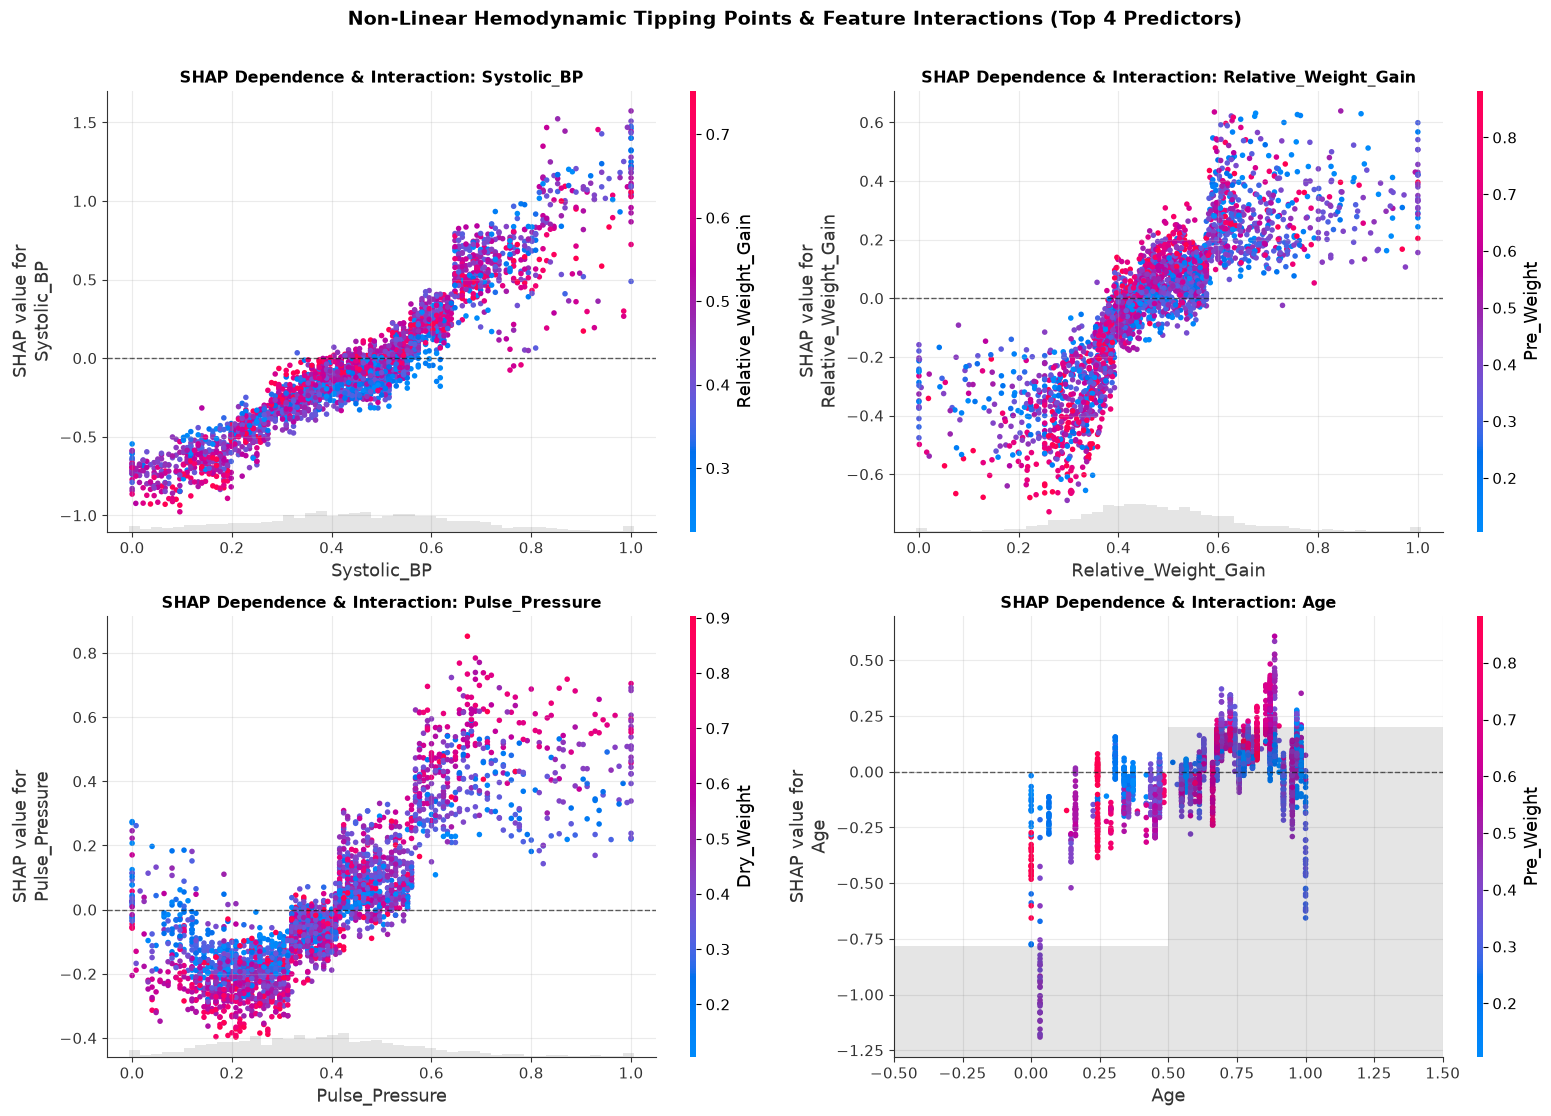

In [5]:
# ==============================================================================
# CELL 4: Non-Linear Feature Dependence & Interaction Analysis (Top 4 Features)
# ==============================================================================
top_4_features = importance_df["Feature"].head(4).tolist()
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes = axes.flatten()

for idx, feat in enumerate(top_4_features):
    ax = axes[idx]
    shap.plots.scatter(shap_exp[:, feat], color=shap_exp, ax=ax, show=False)
    ax.axhline(0, color="black", linestyle="--", linewidth=1.0, alpha=0.6)
    ax.set_title(
        f"SHAP Dependence & Interaction: {feat}", fontsize=11.5, fontweight="bold")
    ax.grid(alpha=0.25)

plt.suptitle("Non-Linear Hemodynamic Tipping Points & Feature Interactions (Top 4 Predictors)",
             fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()